# Lecture 17, Statistical background for downscaling

> The probability and statistics that every bias-correction and downscaling method in Lectures 18&ndash;23 is built from

Lecture 14 ended with the gap between a climate model and a catchment, and said that bias correction and statistical downscaling close it. Every method that does so is built from the same small toolkit: a **distribution** fitted to a sample, a **comparison** of the fitted curve with the data, a **joint distribution** of two variables, and a **random number generator** that draws from a fitted distribution. This lecture builds that toolkit once, on a rainfall record and a temperature record, so that Lectures 18&ndash;23 can use it without stopping to explain.

Think of the questions a downscaler asks:

- On a monsoon day, is it wet or dry, and if wet, **how much** rain falls? Which curve describes the amounts?
- A model's rainfall has a different distribution from the gauge. How do I **measure** the difference?
- A model gives the large-scale temperature. What is the **distribution of the station temperature given it**?
- How do I generate many plausible rainy seasons from a fitted model, and how do I **map one distribution onto another**?

By the end of this lecture you should be able to:

1. read a probability density function (pdf) and a cumulative distribution function (CDF), and compute the mean, variance, skewness and quantiles,
2. choose a distribution for wet-day occurrence, temperature, rainfall amount and extremes, and state its parameters,
3. **derive** the maximum-likelihood estimates of the normal and exponential distributions, and fit a gamma by moments and by maximum likelihood,
4. build an empirical CDF with plotting positions and judge a fit with a quantile&ndash;quantile (QQ) plot and a Kolmogorov&ndash;Smirnov distance,
5. **derive** the conditional distribution of a bivariate normal, which is the basis of regression downscaling (Lecture 19),
6. **derive** the inverse-transform method and use it to simulate rainfall, and recognise it as the second half of quantile mapping (Lecture 18).

All data in this lecture are **synthetic**: they were generated with a fixed random seed to look like a monsoon-season rain gauge and a model&ndash;station temperature pair. The files are in `data/downscaling/lec17/`. To use real data, replace the daily rainfall column by an IMD gridded or station series, and the temperature pair by a CMIP6 or NEX-GDDP-CMIP6 seasonal mean and the matching station mean. Every calculation here is also laid out cell by cell in the companion spreadsheet `lec17_worked_examples.xlsx` (Section 8).

In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy pandas matplotlib scipy

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special, optimize

BASE = "data/downscaling/lec17/"
RAW = "https://raw.githubusercontent.com/drvivekhydro/hydroclimatology/main/data/downscaling/lec17/"

def load(name):
    """Read a CSV from the repository folder, or from GitHub if it is not there (e.g. on Colab)."""
    try:
        return pd.read_csv(BASE + name)
    except FileNotFoundError:
        return pd.read_csv(RAW + name)

daily = load("daily_rain.csv")                    # 120 monsoon-season days, synthetic
temps = load("seasonal_temperature_pairs.csv")    # 40 seasons of model and station temperature, synthetic
uni = load("uniform_numbers.csv")                 # 20 fixed uniform random numbers, synthetic

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
print(daily.head(8).to_string(index=False))

 day  rain_mm
   1     6.86
   2     4.26
   3     6.03
   4     0.00
   5    21.40
   6     0.00
   7    18.96
   8     8.51


# 1) Random variables, pdf, CDF and their descriptors

A **random variable** $X$ is a quantity whose value we cannot predict but whose behaviour we can describe, such as the rain on a given day. Two functions describe it completely.

The **cumulative distribution function** (CDF) is the probability of not exceeding a value,

$$F(x) = P(X \le x),$$

which rises from 0 to 1. For a continuous variable the **probability density function** (pdf) is its slope, $f(x) = dF/dx$, so that the probability of landing in a small interval $dx$ is $f(x)\,dx$ and the total area under $f$ is 1. The **quantile function** is the inverse of the CDF, $x_p = F^{-1}(p)$: the value that is exceeded with probability $1-p$. The 0.99 quantile of daily rain is the rainfall that is exceeded on 1 percent of wet days. Quantiles are what engineers read from a distribution, and Section 7 will show that the quantile function is also how we *simulate*.

Four numbers summarise the shape. With $E[\cdot]$ meaning the probability-weighted average,

| Descriptor | Definition | Tells you |
|:--|:--|:--|
| mean $\mu$ | $\int x f(x)\,dx$ | the centre (units of $X$) |
| variance $\sigma^2$ | $E[(X-\mu)^2]$ | the spread (units of $X^2$); $\sigma$ is the standard deviation |
| skewness $\gamma$ | $E[(X-\mu)^3]/\sigma^3$ | asymmetry (no units): positive = long right tail |
| quantile $x_p$ | $F^{-1}(p)$ | the value not exceeded with probability $p$ |

**Rainfall is not a single variable.** On any day the rain is exactly zero with some probability $1-p$, and otherwise positive. Downscaling therefore treats rainfall in two steps: an **occurrence** variable (wet or dry, a Bernoulli variable, Section 2) and a **wet-day amount** (a continuous positive variable). The data below are 120 synthetic monsoon days.

days = 120,  wet days = 68,  wet-day probability p = 0.567
wet-day amounts: mean = 9.36 mm, sd = 9.68 mm, skewness = 1.70
quantiles  x_0.50 =   6.0 mm  x_0.90 =  22.1 mm  x_0.95 =  29.2 mm  x_0.99 =  41.0 mm


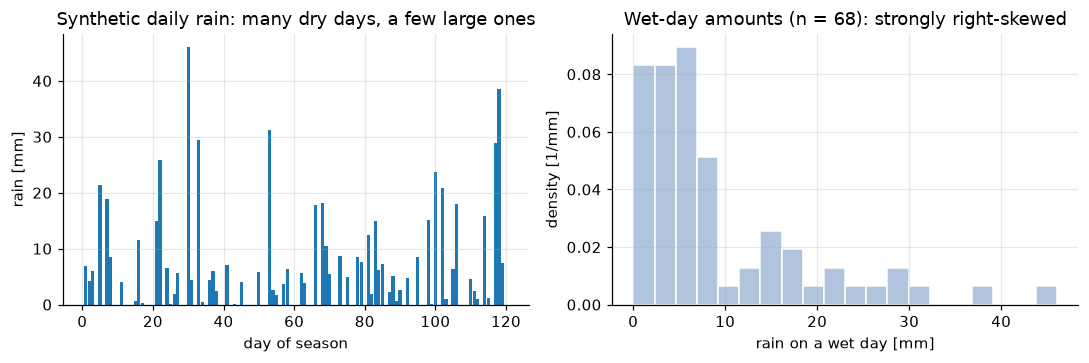

In [3]:
rain = daily["rain_mm"].to_numpy()
wet = rain > 0
x = rain[wet]                      # wet-day amounts [mm]
n = len(x)
p_wet = wet.mean()
print(f"days = {len(rain)},  wet days = {n},  wet-day probability p = {p_wet:.3f}")
print(f"wet-day amounts: mean = {x.mean():.2f} mm, sd = {x.std(ddof=1):.2f} mm, skewness = {stats.skew(x):.2f}")
q = [0.5, 0.9, 0.95, 0.99]
print("quantiles  " + "  ".join(f"x_{pp:.2f} = {np.quantile(x, pp):5.1f} mm" for pp in q))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(daily["day"], rain, color="tab:blue", width=0.9)
ax[0].set(xlabel="day of season", ylabel="rain [mm]", title="Synthetic daily rain: many dry days, a few large ones")
ax[1].hist(x, bins=20, density=True, color="lightsteelblue", edgecolor="white")
ax[1].set(xlabel="rain on a wet day [mm]", ylabel="density [1/mm]", title=f"Wet-day amounts (n = {n}): strongly right-skewed")
fig.tight_layout();

The wet-day amounts are strongly skewed: the median is far below the mean and a few days carry most of the rain. A normal distribution, which is symmetric and can go negative, cannot describe that. We need a family of curves on $x > 0$ with a long right tail, which is the subject of the next section.

# 2) The distributions a downscaler actually uses

A distribution is chosen by the **kind of variable** it must describe (a yes/no, a count, a positive amount, a block maximum) and by the **shape** of the data. The table lists the six that cover most of Lectures 18&ndash;23. In each, a *parameter* is a number that fixes the curve inside its family.

| Distribution | pdf or pmf | Parameters | Mean, variance | Used for |
|:--|:--|:--|:--|:--|
| **Bernoulli** | $P(I=1)=p,\ P(I=0)=1-p$ | $p$ | $p,\ p(1-p)$ | wet or dry on a day |
| **Binomial** | $P(K=k)=\binom{n}{k}p^{k}(1-p)^{n-k}$ | $n,\,p$ | $np,\ np(1-p)$ | number of wet days among $n$ independent days |
| **Normal** | $\dfrac{1}{\sigma\sqrt{2\pi}}\exp\!\left[-\dfrac{(x-\mu)^2}{2\sigma^2}\right]$ | $\mu,\,\sigma$ | $\mu,\ \sigma^2$ | seasonal or monthly mean temperature (sums and averages tend to the normal, by the central limit theorem) |
| **Lognormal** | normal pdf of $\ln x$, divided by $x$ | $\mu,\,\sigma$ of $\ln X$ | $e^{\mu+\sigma^2/2}$ | positive, right-skewed variables such as streamflow: take $\ln X$ and use the normal |
| **Exponential** | $\dfrac{1}{\beta}e^{-x/\beta},\ x\ge 0$ | scale $\beta$ [mm] | $\beta,\ \beta^2$ | rainfall amounts when the standard deviation is about equal to the mean; waiting times |
| **Gamma** | $\dfrac{x^{\alpha-1}e^{-x/\beta}}{\Gamma(\alpha)\,\beta^{\alpha}},\ x>0$ | shape $\alpha$, scale $\beta$ [mm] | $\alpha\beta,\ \alpha\beta^{2}$ | wet-day rainfall: flexible skew, skewness $2/\sqrt{\alpha}$ |
| **GEV** | $F(x)=\exp\!\left\{-\left[1+\xi\dfrac{x-\mu}{\sigma}\right]^{-1/\xi}\right\}$ | location $\mu$, scale $\sigma$, shape $\xi$ | (not needed) | annual maxima of rain or flow |
| **Gumbel** | $F(x)=\exp\!\left[-e^{-(x-\mu)/\sigma}\right]$ | $\mu,\,\sigma$ | | the GEV with $\xi\to 0$: the simplest model of annual maxima |

Points worth remembering.

- The **gamma** contains the exponential: with $\alpha=1$ the gamma pdf is $e^{-x/\beta}/\beta$. For $\alpha<1$ the pdf is highest at zero and falls steeply (lots of light rain days, which is how daily rainfall behaves), for $\alpha>1$ it has a mode away from zero. The gamma is the workhorse of rainfall-amount models and of quantile mapping for precipitation.
- The **lognormal** is the same idea for flows: if $\ln Q$ is normal, then every tool for the normal applies to $\ln Q$.
- **Extremes** are not described by the distribution of all days but of block maxima (for example the largest daily rain of each year). The GEV is the limiting family for such maxima. For a return period $T$ years the annual maximum is exceeded with probability $1/T$, so $F(x_T) = 1-1/T$. For the Gumbel, solving $\exp[-e^{-(x_T-\mu)/\sigma}] = 1-1/T$ gives $x_T = \mu - \sigma\ln\!\left[-\ln(1-1/T)\right]$.
- **Watch the sign convention** of the GEV shape. The convention above, $\xi>0$ for a heavy upper tail, is the one used in most hydrology and statistics software. Some texts, including the reference book for this block, write the shape with the opposite sign. Check which one a formula or a library uses before comparing numbers.

Gumbel return levels for T = 10, 50, 100 years: [100.5 130.2 142.8] mm


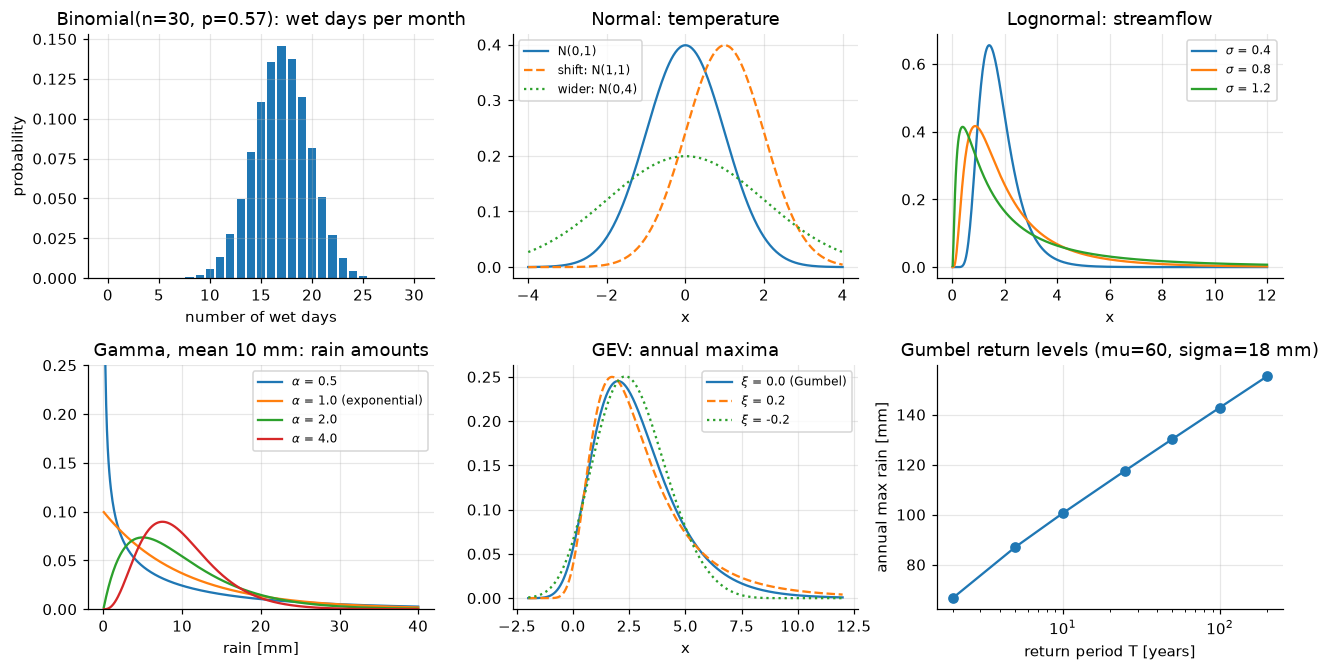

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(12, 6.2))

# Binomial: wet days in a 30-day month with the p of our record
k = np.arange(0, 31)
ax[0, 0].bar(k, stats.binom.pmf(k, 30, p_wet), color="tab:blue")
ax[0, 0].set(title=f"Binomial(n=30, p={p_wet:.2f}): wet days per month", xlabel="number of wet days", ylabel="probability")

# Normal and lognormal
xx = np.linspace(-4, 4, 300)
ax[0, 1].plot(xx, stats.norm.pdf(xx), label="N(0,1)")
ax[0, 1].plot(xx, stats.norm.pdf(xx, 1, 1), "--", label="shift: N(1,1)")
ax[0, 1].plot(xx, stats.norm.pdf(xx, 0, 2), ":", label="wider: N(0,4)")
ax[0, 1].set(title="Normal: temperature", xlabel="x"); ax[0, 1].legend(fontsize=8)

xl = np.linspace(0.01, 12, 400)
for s_ in (0.4, 0.8, 1.2):
    ax[0, 2].plot(xl, stats.lognorm.pdf(xl, s=s_, scale=np.exp(0.5)), label=f"$\\sigma$ = {s_}")
ax[0, 2].set(title="Lognormal: streamflow", xlabel="x"); ax[0, 2].legend(fontsize=8)

# Gamma family (alpha = 1 is the exponential), same mean 10 mm
xg = np.linspace(0.05, 40, 400)
for a_ in (0.5, 1.0, 2.0, 4.0):
    ax[1, 0].plot(xg, stats.gamma.pdf(xg, a_, scale=10 / a_), label=f"$\\alpha$ = {a_}" + (" (exponential)" if a_ == 1 else ""))
ax[1, 0].set(title="Gamma, mean 10 mm: rain amounts", xlabel="rain [mm]", ylim=(0, 0.25)); ax[1, 0].legend(fontsize=8)

# GEV family; scipy's shape c is minus the xi used in the table
xe = np.linspace(-2, 12, 400)
for xi, ls in ((0.0, "-"), (0.2, "--"), (-0.2, ":")):
    ax[1, 1].plot(xe, stats.genextreme.pdf(xe, c=-xi, loc=2, scale=1.5), ls, label=f"$\\xi$ = {xi}" + (" (Gumbel)" if xi == 0 else ""))
ax[1, 1].set(title="GEV: annual maxima", xlabel="x"); ax[1, 1].legend(fontsize=8)

# Return level of the Gumbel, formula against scipy
T = np.array([2, 5, 10, 25, 50, 100, 200])
mu_g, sg = 60.0, 18.0
xT = mu_g - sg * np.log(-np.log(1 - 1 / T))
assert np.allclose(xT, stats.gumbel_r.ppf(1 - 1 / T, loc=mu_g, scale=sg))
ax[1, 2].semilogx(T, xT, "o-")
ax[1, 2].set(title="Gumbel return levels (mu=60, sigma=18 mm)", xlabel="return period T [years]", ylabel="annual max rain [mm]")
fig.tight_layout();
print("Gumbel return levels for T = 10, 50, 100 years:", np.round(xT[[2, 4, 5]], 1), "mm")

# 3) Estimating the parameters

A distribution family has free parameters, and we choose them so that the curve matches the sample $x_1,\dots,x_n$. Two standard rules.

**Method of moments (MoM).** Write the population mean and variance as functions of the parameters, replace them by the sample mean $\bar{x}=\frac1n\sum x_i$ and sample variance $s^2=\frac{1}{n-1}\sum(x_i-\bar x)^2$, and solve. It is quick and can be done by hand or in a spreadsheet.

**Maximum likelihood (MLE).** For independent observations the **likelihood** of the parameters $\theta$ is the product of the densities, $L(\theta)=\prod_i f(x_i\mid\theta)$: how plausible the sample is under those parameters. We choose the $\theta$ that makes the sample most plausible. Products of many small numbers underflow and are awkward to differentiate, so we maximise the **log-likelihood** $\ell(\theta)=\sum_i \ln f(x_i\mid\theta)$, which has its maximum at the same place because $\ln$ is increasing.

### Derivation A: normal

For $f(x)=\frac{1}{\sigma\sqrt{2\pi}}\exp\left[-\frac{(x-\mu)^2}{2\sigma^2}\right]$,

$$\ell(\mu,\sigma^2) = -\frac n2\ln(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_i (x_i-\mu)^2 .$$

Setting $\partial\ell/\partial\mu = \frac{1}{\sigma^2}\sum_i(x_i-\mu)=0$ gives $\hat\mu=\bar x$. Setting $\partial\ell/\partial\sigma^2 = -\frac{n}{2\sigma^2}+\frac{1}{2\sigma^4}\sum_i(x_i-\mu)^2=0$ gives $\hat\sigma^2=\frac1n\sum_i(x_i-\bar x)^2$. For the normal, MoM and MLE agree, except that the MLE divides by $n$ whereas the usual sample variance divides by $n-1$ (the MLE is slightly biased low for small $n$).

### Derivation B: exponential

For $f(x)=\frac1\beta e^{-x/\beta}$, $\ell(\beta) = -n\ln\beta - \frac1\beta\sum_i x_i$. Then $\dfrac{d\ell}{d\beta} = -\dfrac n\beta + \dfrac{1}{\beta^2}\sum_i x_i = 0$ gives $\hat\beta=\bar x$. Since the exponential mean is $\beta$, the moment estimate is also $\bar x$: again MoM and MLE coincide.

### Gamma, by moments

With mean $\alpha\beta$ and variance $\alpha\beta^2$: dividing, $\beta = \sigma^2/\mu$ and $\alpha=\mu/\beta=\mu^2/\sigma^2$, so

$$\hat\alpha_{\text{MoM}}=\frac{\bar x^{2}}{s^{2}},\qquad \hat\beta_{\text{MoM}}=\frac{s^{2}}{\bar x}.$$

### Gamma, by maximum likelihood

$$\ell(\alpha,\beta)= -n\ln\Gamma(\alpha) - n\alpha\ln\beta + (\alpha-1)\sum_i\ln x_i - \frac1\beta\sum_i x_i .$$

Differentiating with respect to $\beta$: $-\frac{n\alpha}{\beta}+\frac{1}{\beta^{2}}\sum x_i=0$, so $\hat\beta=\bar x/\hat\alpha$ (the fitted mean $\alpha\beta$ always equals the sample mean). Substituting this into the derivative with respect to $\alpha$, $-n\psi(\alpha)-n\ln\beta+\sum\ln x_i=0$ with $\psi=\Gamma'/\Gamma$ the digamma function, gives one equation in $\alpha$:

$$\ln\alpha-\psi(\alpha)=s,\qquad s=\ln\bar x-\frac1n\sum_i\ln x_i .$$

$s>0$ for any non-constant sample (the log of the average exceeds the average of the logs), and there is no closed-form solution, so it is solved numerically. A standard closed-form approximation, accurate to about 1 percent, is $\hat\alpha\approx\dfrac{1+\sqrt{1+4s/3}}{4s}$, which is good enough for a spreadsheet; and `scipy.optimize.brentq` solves the exact equation in one line. (The reference book also introduces metaheuristic optimisers, such as the genetic algorithm, for models where no such equation exists; for the distributions here a root finder is all that is needed.)

The code fits the wet-day amounts and checks each derivation numerically.

In [5]:
# --- numerical checks of the derivations -------------------------------------------------------
rng = np.random.default_rng(1)
z = rng.normal(5.0, 2.0, 40)
mu_hat, var_hat = z.mean(), z.var(ddof=0)                    # derived: mean and variance with divisor n
loc_, sc_ = stats.norm.fit(z)                                # scipy's numerical MLE
print(f"normal : derived (mu, sigma^2) = ({mu_hat:.4f}, {var_hat:.4f});  scipy MLE = ({loc_:.4f}, {sc_**2:.4f})")
print(f"exponential: derived beta = xbar = {x.mean():.4f};  scipy MLE = {stats.expon.fit(x, floc=0)[1]:.4f}")

# --- gamma fits to the wet-day amounts ---------------------------------------------------------
xb, s2, mlog = x.mean(), x.var(ddof=1), np.log(x).mean()
alpha_mom, beta_mom = xb**2 / s2, s2 / xb

s_stat = np.log(xb) - mlog
alpha_thom = (1 + np.sqrt(1 + 4 * s_stat / 3)) / (4 * s_stat)         # closed-form approximation (spreadsheet)
alpha_mle = optimize.brentq(lambda a: np.log(a) - special.digamma(a) - s_stat, 0.05, 50)   # exact root
beta_mle, beta_thom = xb / alpha_mle, xb / alpha_thom

def gamma_ll(a, b, data=x):
    """Log-likelihood sum of ln f(x_i | a, b) of the gamma."""
    return stats.gamma.logpdf(data, a, scale=b).sum()

def gamma_ll_profile(a, data=x):
    """Closed form of the log-likelihood after substituting beta = xbar/alpha (used for the spreadsheet grid)."""
    m = len(data)
    return -m * special.gammaln(a) - m * a * np.log(data.mean() / a) + (a - 1) * np.log(data).sum() - m * a

assert np.isclose(gamma_ll_profile(alpha_mle), gamma_ll(alpha_mle, beta_mle))
a_sp, _, b_sp = stats.gamma.fit(x, floc=0)                                           # scipy for comparison

fits = pd.DataFrame({
    "alpha": [alpha_mom, alpha_thom, alpha_mle, a_sp],
    "beta [mm]": [beta_mom, beta_thom, beta_mle, b_sp],
    "mean alpha*beta [mm]": [alpha_mom * beta_mom, alpha_thom * beta_thom, alpha_mle * beta_mle, a_sp * b_sp],
    "log-likelihood": [gamma_ll(alpha_mom, beta_mom), gamma_ll(alpha_thom, beta_thom), gamma_ll(alpha_mle, beta_mle), gamma_ll(a_sp, b_sp)],
}, index=["gamma MoM", "gamma MLE, closed form (sheet)", "gamma MLE, exact root", "gamma MLE, scipy"])
print(fits.round(4).to_string())
print(f"exponential: beta = {xb:.3f} mm, log-likelihood = {stats.expon.logpdf(x, scale=xb).sum():.3f}")
print(f"s = {s_stat:.5f};  sample mean {xb:.4f} mm;  the spreadsheet sheet Gamma_fit holds the same numbers (cells K13, K14, K18, K19, K25).")

normal : derived (mu, sigma^2) = (5.0056, 3.4590);  scipy MLE = (5.0056, 3.4590)
exponential: derived beta = xbar = 9.3619;  scipy MLE = 9.3619
                                 alpha  beta [mm]  mean alpha*beta [mm]  log-likelihood
gamma MoM                       0.9348    10.0148                9.3619       -219.9001
gamma MLE, closed form (sheet)  0.9191    10.1855                9.3619       -219.8849
gamma MLE, exact root           0.9086    10.3031                9.3619       -219.8819
gamma MLE, scipy                0.9086    10.3031                9.3619       -219.8819
exponential: beta = 9.362 mm, log-likelihood = -220.092
s = 0.64262;  sample mean 9.3619 mm;  the spreadsheet sheet Gamma_fit holds the same numbers (cells K13, K14, K18, K19, K25).


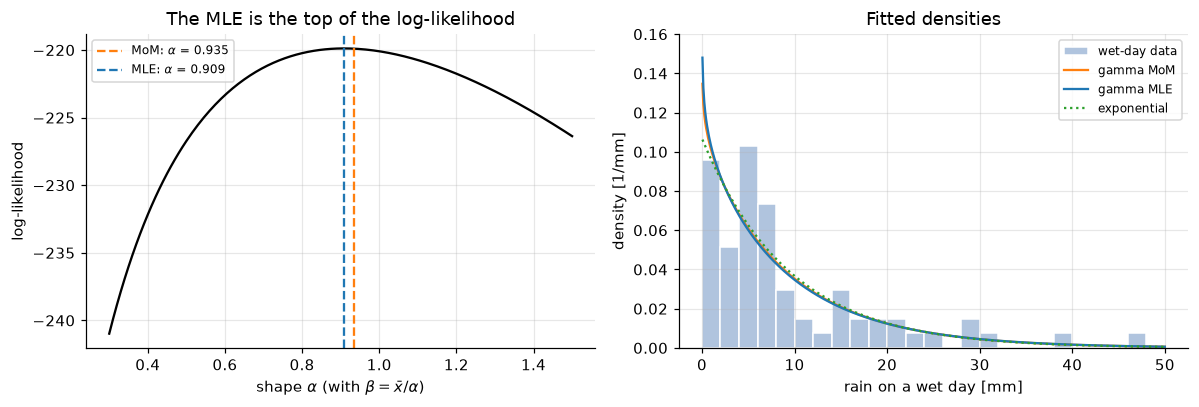

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

aa = np.linspace(0.3, 1.5, 241)
ax[0].plot(aa, [gamma_ll_profile(a) for a in aa], color="k")
for a_, lab, c in ((alpha_mom, "MoM", "tab:orange"), (alpha_mle, "MLE", "tab:blue")):
    ax[0].axvline(a_, color=c, ls="--", label=f"{lab}: $\\alpha$ = {a_:.3f}")
ax[0].set(xlabel="shape $\\alpha$ (with $\\beta=\\bar x/\\alpha$)", ylabel="log-likelihood", title="The MLE is the top of the log-likelihood")
ax[0].legend(fontsize=8)

xp = np.linspace(0.05, 50, 500)
ax[1].hist(x, bins=25, range=(0, 50), density=True, color="lightsteelblue", edgecolor="white", label="wet-day data")
ax[1].plot(xp, stats.gamma.pdf(xp, alpha_mom, scale=beta_mom), "tab:orange", label="gamma MoM")
ax[1].plot(xp, stats.gamma.pdf(xp, alpha_mle, scale=beta_mle), "tab:blue", label="gamma MLE")
ax[1].plot(xp, stats.expon.pdf(xp, scale=xb), "tab:green", ls=":", label="exponential")
ax[1].set(xlabel="rain on a wet day [mm]", ylabel="density [1/mm]", ylim=(0, 0.16), title="Fitted densities"); ax[1].legend(fontsize=8)
fig.tight_layout();

For this sample the two gamma fits are close. This is **not** a general rule, so here is the reason MLE is preferred, tested by simulation (a **Monte Carlo experiment**, Section 7): draw many samples of the same size from a gamma with a *known* shape, estimate the shape each time by both methods, and see which estimate is more reliable. The sample variance in MoM is dominated by the few largest values, while the MLE uses $\ln x$, which weights all values more evenly.

In [7]:
rng = np.random.default_rng(2)
a_true, b_true, reps = 0.8, 11.7, 3000
S = rng.gamma(a_true, b_true, size=(reps, n))
xbar_s = S.mean(axis=1)
a_mom_s = xbar_s**2 / S.var(axis=1, ddof=1)
s_s = np.log(xbar_s) - np.log(S).mean(axis=1)
a_mle_s = (1 + np.sqrt(1 + 4 * s_s / 3)) / (4 * s_s)

print(f"true shape = {a_true}, sample size n = {n}, {reps} repetitions")
for name, a_ in (("MoM", a_mom_s), ("MLE (closed form)", a_mle_s)):
    print(f"{name:18s}: mean estimate = {a_.mean():.3f},  standard deviation = {a_.std():.3f},  "
          f"RMSE = {np.sqrt(((a_ - a_true)**2).mean()):.3f}")

true shape = 0.8, sample size n = 68, 3000 repetitions
MoM               : mean estimate = 0.856,  standard deviation = 0.195,  RMSE = 0.203
MLE (closed form) : mean estimate = 0.842,  standard deviation = 0.125,  RMSE = 0.132


The maximum-likelihood shape has the smaller scatter, which is why it is the default in software (`scipy.stats.gamma.fit`). The moment estimate remains useful as a starting value and for hand calculation.

# 4) The empirical distribution and plotting positions

Before trusting a fitted curve we need a curve that comes from the data alone. The **empirical CDF** of a sample is the fraction of observations not exceeding $x$,

$$F_n(x)=\frac1n\,\#\{i: x_i\le x\},$$

a staircase that jumps by $1/n$ at each observation. Sort the sample, $x_{(1)}\le x_{(2)}\le\dots\le x_{(n)}$, so that $x_{(i)}$ has **rank** $i$. Just after $x_{(i)}$ the staircase equals $i/n$, which would put the largest value at probability 1: the model would say nothing larger can ever happen, and the return period $1/(1-F)$ would be infinite. That is why hydrology plots each sorted value at a **plotting position** strictly between 0 and 1. The simplest is the Weibull position

$$\hat F(x_{(i)}) = \frac{i}{n+1}.$$

**Why $n+1$?** If the $n$ observations were uniform on $(0,1)$ (Section 7 shows that $F(X)$ is uniform), they would cut the interval into $n+1$ gaps. By symmetry the gaps have equal expected length $1/(n+1)$, so the $i$-th smallest sits on average at $i/(n+1)$: the plotting position is the *expected* value of $F$ at the $i$-th point, and the largest of $n$ annual values has a return period of $n+1$ years rather than infinity. Other conventions, such as $(i-0.5)/n$, differ slightly and matter only in the extreme tails; spreadsheet functions have their own (Excel's `PERCENTRANK.INC` uses $(i-1)/(n-1)$, so it gives exactly 0 and 1 at the ends).

rank i : [1, 34, 68]
i/n          : [0.015 0.5   1.   ]
i/(n+1)      : [0.014 0.493 0.986]
(i-0.5)/n    : [0.007 0.493 0.993]
(i-1)/(n-1)  : [0.    0.493 1.   ]  (Excel PERCENTRANK.INC without ties)
mean of the i-th smallest of n uniforms, i = 1, n/2, n: [0.015 0.493 0.986]


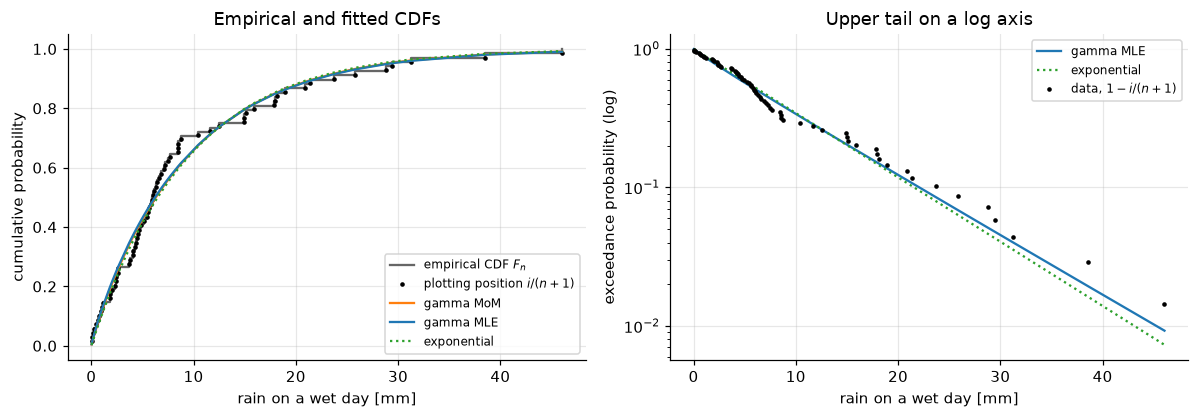

In [8]:
xs = np.sort(x)
i = np.arange(1, n + 1)
pp = i / (n + 1)

print("rank i :", [1, n // 2, n])
print("i/n          :", np.round([1 / n, (n // 2) / n, 1.0], 3))
print("i/(n+1)      :", np.round([1 / (n + 1), (n // 2) / (n + 1), n / (n + 1)], 3))
print("(i-0.5)/n    :", np.round([0.5 / n, (n // 2 - 0.5) / n, (n - 0.5) / n], 3))
print("(i-1)/(n-1)  :", np.round([0.0, (n // 2 - 1) / (n - 1), 1.0], 3), " (Excel PERCENTRANK.INC without ties)")

# quick check of "E[U_(i)] = i/(n+1)" by simulation
U = np.sort(np.random.default_rng(3).random((20000, n)), axis=1)
print("mean of the i-th smallest of n uniforms, i = 1, n/2, n:", np.round(U.mean(axis=0)[[0, n // 2 - 1, n - 1]], 3))

F_mom = stats.gamma.cdf(xs, alpha_mom, scale=beta_mom)
F_mle = stats.gamma.cdf(xs, alpha_mle, scale=beta_mle)
F_exp = stats.expon.cdf(xs, scale=xb)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
ax[0].step(xs, i / n, where="post", color="0.4", label="empirical CDF $F_n$")
ax[0].plot(xs, pp, "k.", ms=4, label="plotting position $i/(n+1)$")
ax[0].plot(xs, F_mom, "tab:orange", label="gamma MoM")
ax[0].plot(xs, F_mle, "tab:blue", label="gamma MLE")
ax[0].plot(xs, F_exp, "tab:green", ls=":", label="exponential")
ax[0].set(xlabel="rain on a wet day [mm]", ylabel="cumulative probability", title="Empirical and fitted CDFs"); ax[0].legend(fontsize=8)
ax[1].plot(xs, 1 - F_mle, "tab:blue", label="gamma MLE")
ax[1].plot(xs, 1 - F_exp, "tab:green", ls=":", label="exponential")
ax[1].plot(xs, 1 - pp, "k.", ms=4, label="data, $1-i/(n+1)$")
ax[1].set_yscale("log")
ax[1].set(xlabel="rain on a wet day [mm]", ylabel="exceedance probability (log)", title="Upper tail on a log axis"); ax[1].legend(fontsize=8)
fig.tight_layout();

On the linear axis the three curves look alike; the log-scaled **upper tail** is where they part, and the tail is what drives floods and design values.

# 5) Is the fit good enough? QQ plots and a KS distance

Two checks should be routine.

**QQ plot.** For each rank $i$ compute the model quantile $F^{-1}(i/(n+1))$ and plot the observed $x_{(i)}$ against it. If the model is right, the points fall on the 1:1 line. A curve that bends *above* the line at the right means the data have a heavier upper tail than the model.

**Kolmogorov&ndash;Smirnov (KS) distance.** The largest vertical gap between the empirical and the fitted CDF,

$$D=\sup_x |F_n(x)-F(x)| = \max_i \max\!\left\{\frac{i}{n}-F(x_{(i)}),\; F(x_{(i)})-\frac{i-1}{n}\right\},$$

the two terms covering the two sides of each step of the staircase. $D$ is a single number in $[0,1]$ that is easy to compute in a spreadsheet and has a known distribution when the parameters were fixed in advance.

**A caution that matters.** The usual KS critical values (about $1.36/\sqrt n$ at the 5 percent level) assume the parameters were *not* estimated from the same sample. When they are, the fitted curve is pulled towards the data and $D$ is smaller than it would otherwise be, so the textbook test is too lenient. The honest fix is a **parametric bootstrap**: simulate many samples from the fitted model, refit each, and see how large $D$ typically gets.

KS distance D: gamma MoM 0.0933,  gamma MLE 0.0910,  exponential 0.0986
cross-check with scipy.stats.kstest (gamma MLE): 0.0910
textbook 5% critical value 1.36/sqrt(n) = 0.1649
bootstrap 95th percentile of D (parameters refitted) = 0.1133  (smaller than the textbook value, as the caution says)
bootstrap p-value of the observed D (gamma, closed-form fit) = 0.23

Quantiles of wet-day rain [mm]:
        data  gamma MLE  exponential
median   6.0        6.2          6.5
90%     22.1       22.1         21.6
95%     29.2       29.0         28.0
99%     41.0       45.3         43.1


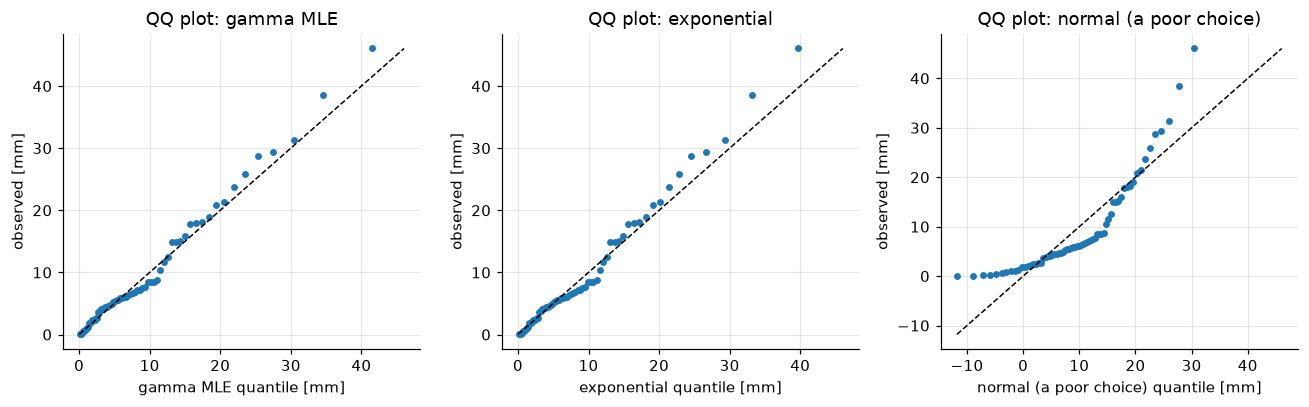

In [9]:
def ks_distance(sample, cdf):
    """KS distance D = max_i max(i/n - F, F - (i-1)/n) for a sorted-sample comparison with a CDF function."""
    s = np.sort(sample); m = len(s); k = np.arange(1, m + 1)
    F = cdf(s)
    return np.max(np.maximum(k / m - F, F - (k - 1) / m))

D_mom = ks_distance(x, lambda t: stats.gamma.cdf(t, alpha_mom, scale=beta_mom))
D_mle = ks_distance(x, lambda t: stats.gamma.cdf(t, alpha_mle, scale=beta_mle))
D_exp = ks_distance(x, lambda t: stats.expon.cdf(t, scale=xb))
print(f"KS distance D: gamma MoM {D_mom:.4f},  gamma MLE {D_mle:.4f},  exponential {D_exp:.4f}")
print(f"cross-check with scipy.stats.kstest (gamma MLE): {stats.kstest(x, 'gamma', args=(alpha_mle, 0, beta_mle)).statistic:.4f}")
print(f"textbook 5% critical value 1.36/sqrt(n) = {1.36 / np.sqrt(n):.4f}")

# parametric bootstrap for the gamma (shape by the closed form, as in the spreadsheet; scale = xbar/shape)
rng = np.random.default_rng(4)
B = 500
Dboot = np.empty(B)
for r in range(B):
    smp = rng.gamma(alpha_mle, beta_mle, n)
    sb = np.log(smp.mean()) - np.log(smp).mean()
    ab = (1 + np.sqrt(1 + 4 * sb / 3)) / (4 * sb)
    Dboot[r] = ks_distance(smp, lambda t: stats.gamma.cdf(t, ab, scale=smp.mean() / ab))
print(f"bootstrap 95th percentile of D (parameters refitted) = {np.quantile(Dboot, 0.95):.4f}  "
      f"(smaller than the textbook value, as the caution says)")
print(f"bootstrap p-value of the observed D (gamma, closed-form fit) = {(Dboot >= D_mle).mean():.2f}")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
for a_, (name, qf) in zip(ax, (("gamma MLE", lambda u_: stats.gamma.ppf(u_, alpha_mle, scale=beta_mle)),
                               ("exponential", lambda u_: stats.expon.ppf(u_, scale=xb)),
                               ("normal (a poor choice)", lambda u_: stats.norm.ppf(u_, xb, x.std(ddof=1))))):
    qm = qf(pp)
    a_.plot(qm, xs, "o", ms=3.5)
    lim = [min(qm.min(), xs.min()), max(qm.max(), xs.max())]
    a_.plot(lim, lim, "k--", lw=1)
    a_.set(xlabel=f"{name} quantile [mm]", ylabel="observed [mm]", title=f"QQ plot: {name}")
fig.tight_layout()

tab = pd.DataFrame({"data": np.quantile(x, [0.5, 0.9, 0.95, 0.99]),
                    "gamma MLE": stats.gamma.ppf([0.5, 0.9, 0.95, 0.99], alpha_mle, scale=beta_mle),
                    "exponential": stats.expon.ppf([0.5, 0.9, 0.95, 0.99], scale=xb)}, index=["median", "90%", "95%", "99%"])
print("\nQuantiles of wet-day rain [mm]:")
print(tab.round(1).to_string())

The normal QQ plot bends strongly (it also predicts negative rain); the gamma and exponential QQ plots stay near the line, with the top two or three points lying a little above it, which with only 68 values is within sampling noise. In the table the **99% quantile** is the place where the models and the data are least certain, because only about one wet day in a hundred, here less than one observation, informs it. Fit the bulk of the distribution well, and treat claims about the extreme tail with suspicion unless you have used an extreme-value model (Section 2) on enough years.

# 6) Two variables together: covariance, correlation and the conditional normal

Downscaling relates **two** things: a large-scale predictor $X$ from a model and a local predictand $Y$ at a station. Two numbers describe how they vary together. The **covariance** is $\mathrm{Cov}(X,Y)=E[(X-\mu_x)(Y-\mu_y)]$ (units of $X$ times units of $Y$) and the **correlation** is the unit-free version,

$$\rho=\frac{\mathrm{Cov}(X,Y)}{\sigma_x\sigma_y},\qquad -1\le\rho\le1.$$

The **bivariate normal** distribution has five parameters, $\mu_x,\mu_y,\sigma_x,\sigma_y,\rho$. Its pdf (in $p$ dimensions, $N_p(\boldsymbol\mu,\Sigma)$ with mean vector $\boldsymbol\mu$ and covariance matrix $\Sigma$) has elliptical contours, tilted when $\rho\ne0$. Its most useful property for us: **its conditional distributions are again normal**, with a mean that is a straight line in the conditioning value. We derive the bivariate case.

### Derivation: $Y$ given $X=x$

Let $b=\rho\sigma_y/\sigma_x$ and define $Z=Y-bX$ (the part of $Y$ that $X$ does not explain).

1. $Z$ is a linear combination of jointly normal variables, so it is normal, with mean $E[Z]=\mu_y-b\mu_x$.
2. Its covariance with $X$ is $\mathrm{Cov}(Z,X)=\mathrm{Cov}(Y,X)-b\,\mathrm{Var}(X)=\rho\sigma_x\sigma_y-\rho\frac{\sigma_y}{\sigma_x}\sigma_x^{2}=0$.
3. For jointly normal variables zero covariance means **independence** (the joint pdf then factorises into a product). So $Z$ is independent of $X$, and learning $X=x$ tells us nothing about $Z$.
4. Since $Y=bX+Z$, given $X=x$ we have $Y=bx+Z$ with $Z$ keeping its own distribution. Therefore $Y\mid X=x$ is normal with

$$\boxed{\;E[Y\mid x]=\mu_y+\rho\frac{\sigma_y}{\sigma_x}(x-\mu_x),\qquad \mathrm{Var}[Y\mid x]=\sigma_y^{2}(1-\rho^{2})\;}$$

where the variance is $\mathrm{Var}(Z)=\sigma_y^2-2b\rho\sigma_x\sigma_y+b^2\sigma_x^2=\sigma_y^2-2\rho^2\sigma_y^2+\rho^2\sigma_y^2$.

**In plain words.** The best prediction of the station value is a straight line through the means with slope $b=\rho\sigma_y/\sigma_x$. The slope is the correlation rescaled by the ratio of the standard deviations, which is exactly the least-squares regression slope, so *linear regression is the conditional mean of a bivariate normal*. The spread of what remains is $\sigma_y\sqrt{1-\rho^2}$, **independent of $x$**: knowing the model value reduces the variance by the fraction $\rho^2$ (the $R^2$ of the regression) but never to zero. Lecture 19 builds regression downscaling on this result, and it shows why a regression *prediction* has too little variance and why the residual spread must be put back (Lecture 21).

For the matrix form with several predictors, $\mu_{Y|x}=\mu_Y+\Sigma_{YX}\Sigma_{XX}^{-1}(x-\mu_X)$ and $\Sigma_{Y|X}=\Sigma_{YY}-\Sigma_{YX}\Sigma_{XX}^{-1}\Sigma_{XY}$, whose variance again does not depend on $x$. We use the scalar case only.

**Example.** $X$ is the model's June&ndash;September mean temperature for the grid cell and $Y$ the station's, over 40 synthetic seasons.

means (model, station) = (27.297, 28.870) degC;  sd = (0.894, 1.023) degC;  rho = 0.7012
conditional mean: E[Y|x] = 6.971 + 0.8023 x ;  conditional sd = 0.729 degC (unconditional sd 1.023)
check, least-squares fit: slope 0.8023, intercept 6.971;  R^2 = 0.492 = fraction of variance explained

brute force near x0 = 28.5: mean = 29.853, sd = 0.798   formula: mean = 29.856, sd = 0.786


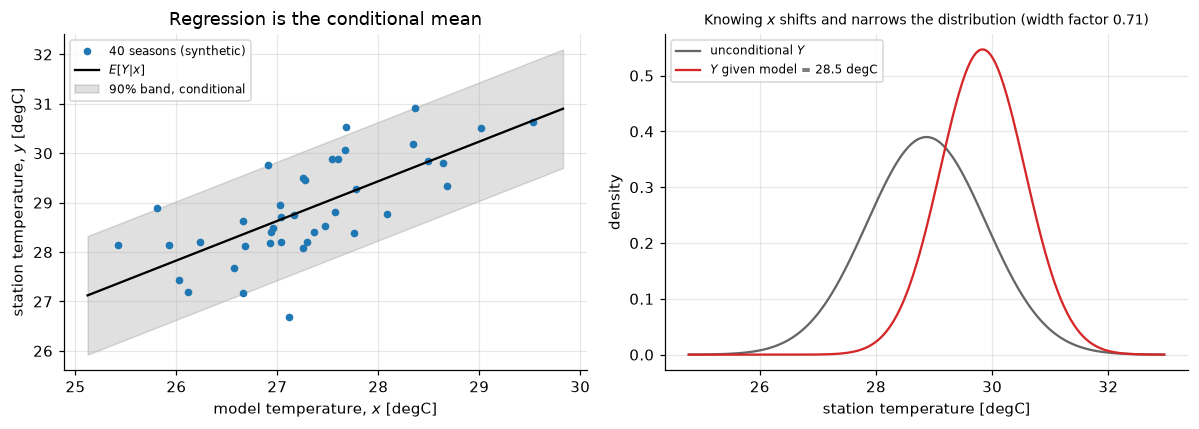

In [10]:
X, Y = temps["model_T_degC"].to_numpy(), temps["station_T_degC"].to_numpy()
mx, my, sx, sy = X.mean(), Y.mean(), X.std(ddof=1), Y.std(ddof=1)
rho = np.corrcoef(X, Y)[0, 1]
b_slope = rho * sy / sx
a_int = my - b_slope * mx
cond_sd = sy * np.sqrt(1 - rho**2)

print(f"means (model, station) = ({mx:.3f}, {my:.3f}) degC;  sd = ({sx:.3f}, {sy:.3f}) degC;  rho = {rho:.4f}")
print(f"conditional mean: E[Y|x] = {a_int:.3f} + {b_slope:.4f} x ;  conditional sd = {cond_sd:.3f} degC (unconditional sd {sy:.3f})")
sl, ic = np.polyfit(X, Y, 1)
print(f"check, least-squares fit: slope {sl:.4f}, intercept {ic:.3f};  R^2 = {rho**2:.3f} = fraction of variance explained")

# Sanity check of the derivation by brute force: simulate a large bivariate normal and look at Y near X = x0
rng = np.random.default_rng(5)
mu_t, sg_x, sg_y, r_t = (27.5, 29.0), 0.9, 1.1, 0.7
cov = [[sg_x**2, r_t * sg_x * sg_y], [r_t * sg_x * sg_y, sg_y**2]]
big = rng.multivariate_normal(mu_t, cov, size=400_000)
x0 = 28.5
sel = big[np.abs(big[:, 0] - x0) < 0.02, 1]
print(f"\nbrute force near x0 = {x0}: mean = {sel.mean():.3f}, sd = {sel.std():.3f}   "
      f"formula: mean = {mu_t[1] + r_t * sg_y / sg_x * (x0 - mu_t[0]):.3f}, sd = {sg_y * np.sqrt(1 - r_t**2):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(X, Y, "o", ms=4, color="tab:blue", label="40 seasons (synthetic)")
xl_ = np.linspace(X.min() - 0.3, X.max() + 0.3, 50)
ax[0].plot(xl_, a_int + b_slope * xl_, "k", label="$E[Y|x]$")
ax[0].fill_between(xl_, a_int + b_slope * xl_ - 1.645 * cond_sd, a_int + b_slope * xl_ + 1.645 * cond_sd, color="k", alpha=0.12, label="90% band, conditional")
ax[0].set(xlabel="model temperature, $x$ [degC]", ylabel="station temperature, $y$ [degC]", title="Regression is the conditional mean"); ax[0].legend(fontsize=8)

yy = np.linspace(my - 4 * sy, my + 4 * sy, 300)
x_cond = 28.5
ax[1].plot(yy, stats.norm.pdf(yy, my, sy), "0.4", label="unconditional $Y$")
ax[1].plot(yy, stats.norm.pdf(yy, a_int + b_slope * x_cond, cond_sd), "tab:red", label=f"$Y$ given model = {x_cond} degC")
ax[1].set(xlabel="station temperature [degC]", ylabel="density", title=f"Knowing $x$ shifts and narrows the distribution (width factor {np.sqrt(1 - rho**2):.2f})"); ax[1].legend(fontsize=8)
ax[1].title.set_fontsize(9)
fig.tight_layout();

The brute-force check (many simulated pairs, keeping those whose $x$ is near $x_0$) agrees with the formula, and the slope from least squares is the same number as $\rho\sigma_y/\sigma_x$. The spreadsheet sheet `Bivariate` repeats the chain with `CORREL`, `SLOPE`, `INTERCEPT`, `RSQ` and `LINEST`.

# 7) Monte Carlo simulation and the inverse-transform method

A **Monte Carlo** simulation answers a question by generating many random samples from a model and looking at the results. To use it we need to draw random numbers from *any* fitted distribution, and the computer supplies only one kind, the **uniform** random number $U$ on $(0,1)$, equally likely anywhere. The **inverse-transform method** converts it.

### Derivation

Let $F$ be a continuous, strictly increasing CDF and $U$ uniform on $(0,1)$. Define $X=F^{-1}(U)$. Then for any $x$

$$P(X\le x)=P\big(F^{-1}(U)\le x\big)=P\big(U\le F(x)\big)=F(x),$$

where the second step applies the increasing function $F$ to both sides of the inequality, and the last step uses $P(U\le u)=u$ for $u\in[0,1]$. So $X$ has CDF $F$. **A uniform number pushed through the inverse CDF has exactly the target distribution.**

The same argument read backwards says that $F(X)$ is uniform for any continuous $X$; we used this in Section 4 when we placed observations at $i/(n+1)$.

**Exponential example.** From $u=1-e^{-x/\beta}$ we solve $x=-\beta\ln(1-u)$. For $\beta=10$ mm and $u=0.5$ this gives $x=10\ln 2=6.93$ mm, the median, as it should: half the draws fall below it. The same $u$ gives the median of any other distribution, because $F^{-1}(0.5)$ is its median. For the gamma, $F^{-1}$ has no formula and is computed numerically (`scipy.stats.gamma.ppf`; `GAMMA.INV` in Excel). A Bernoulli (wet/dry) variable is the discrete case: call the day wet if $u\le p$, which happens with probability $p$. (In the table below the same $u$ is reused for the wet/dry flag only to show the mechanics; in a real simulation, and in the season experiment after it, occurrence and amount use **separate** uniform numbers.)

The code draws rainfall with the 20 fixed uniform numbers of the spreadsheet, then with many numbers to confirm the shape.

    u  exponential [mm]  gamma MLE [mm]  empirical inverse [mm]  wet?
0.507             6.631           6.379                   6.030     1
0.922            23.931          24.607                  25.404     0
0.455             5.679           5.408                   5.599     1
0.401             4.796           4.516                   4.871     1
0.959            29.858          30.963                  29.873     0
0.322             3.642           3.363                   4.199     1
0.354             4.095           3.813                   4.427     1
0.140             1.414           1.211                   1.414     1
...
means of the 20 draws: exponential 8.67, gamma 8.63, empirical 8.85 mm (observed wet-day mean 9.36); fraction wet 0.65 (p = 0.57).  Same columns as sheet InvTransform.
round trip F(F^-1(u)) - u, largest absolute error: 1.9984014443252818e-15

20000 draws: gamma mean 9.30 (theory 9.36), variance 98.1 (theory 96.5); KS distance to the exponential CDF 0.0069


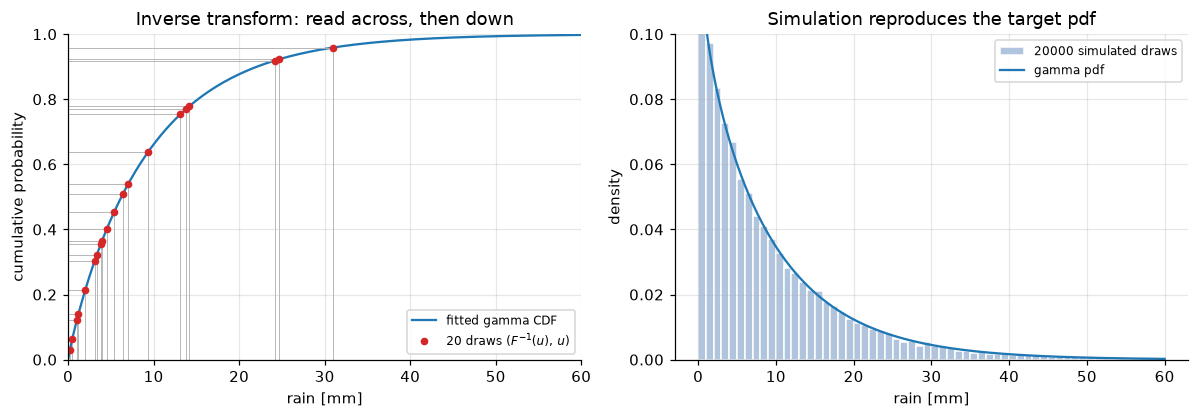

In [11]:
u = uni["u"].to_numpy()                                   # the same 20 numbers as Data!I in the spreadsheet
exp_draw = -xb * np.log(1 - u)                            # derived formula
gam_draw = stats.gamma.ppf(u, alpha_mle, scale=beta_mle)  # numerical inverse of the gamma CDF
emp_draw = np.quantile(x, u)                              # inverse of the EMPIRICAL CDF (linear interpolation, as PERCENTILE.INC)
wet_flag = (u <= p_wet).astype(int)

tab = pd.DataFrame({"u": u, "exponential [mm]": exp_draw, "gamma MLE [mm]": gam_draw, "empirical inverse [mm]": emp_draw, "wet?": wet_flag})
print(tab.round(3).head(8).to_string(index=False))
print(f"...\nmeans of the 20 draws: exponential {exp_draw.mean():.2f}, gamma {gam_draw.mean():.2f}, empirical {emp_draw.mean():.2f} mm (observed wet-day mean {xb:.2f}); "
      f"fraction wet {wet_flag.mean():.2f} (p = {p_wet:.2f}).  Same columns as sheet InvTransform.")
print("round trip F(F^-1(u)) - u, largest absolute error:", np.abs(stats.gamma.cdf(gam_draw, alpha_mle, scale=beta_mle) - u).max())

# many draws: the histogram should follow the pdf and the KS distance should be tiny
rng = np.random.default_rng(6)
N = 20000
UU = rng.random(N)
big_exp = -xb * np.log(1 - UU)
big_gam = stats.gamma.ppf(UU, alpha_mle, scale=beta_mle)
print(f"\n{N} draws: gamma mean {big_gam.mean():.2f} (theory {alpha_mle*beta_mle:.2f}), variance {big_gam.var():.1f} (theory {alpha_mle*beta_mle**2:.1f}); "
      f"KS distance to the exponential CDF {stats.kstest(big_exp, 'expon', args=(0, xb)).statistic:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
cg = np.linspace(0.02, 60, 300)
ax[0].plot(cg, stats.gamma.cdf(cg, alpha_mle, scale=beta_mle), "tab:blue", label="fitted gamma CDF")
for uu_, xx_ in zip(u, gam_draw):
    ax[0].plot([0, xx_, xx_], [uu_, uu_, 0], color="0.7", lw=0.6)
ax[0].plot(gam_draw, u, "o", color="tab:red", ms=4, label="20 draws $(F^{-1}(u),\\,u)$")
ax[0].set(xlim=(0, 60), ylim=(0, 1), xlabel="rain [mm]", ylabel="cumulative probability", title="Inverse transform: read across, then down"); ax[0].legend(fontsize=8, loc="lower right")
ax[1].hist(big_gam, bins=60, range=(0, 60), density=True, color="lightsteelblue", edgecolor="white", label=f"{N} simulated draws")
ax[1].plot(cg, stats.gamma.pdf(cg, alpha_mle, scale=beta_mle), "tab:blue", label="gamma pdf")
ax[1].set(xlabel="rain [mm]", ylabel="density", ylim=(0, 0.1), title="Simulation reproduces the target pdf"); ax[1].legend(fontsize=8)
fig.tight_layout();

### A first Monte Carlo experiment: how variable is a monsoon season?

Combine the two pieces of Section 2: each day is wet with probability $p$, and a wet day gets a gamma amount. We simulate many 120-day seasons and look at the distribution of the **seasonal total**. This is the simplest *weather generator* (Lecture 21 adds day-to-day persistence of wet spells, which this version ignores, so it understates how clustered rain is).

observed (one synthetic) season total: 637 mm
simulated totals: mean 635 mm, sd 95 mm, 5-95% range 490-796 mm
theory (independent days): mean 637 mm
P(a day has more than 50 mm) = 0.0035   (theory p*(1-F(50)) = 0.0035)


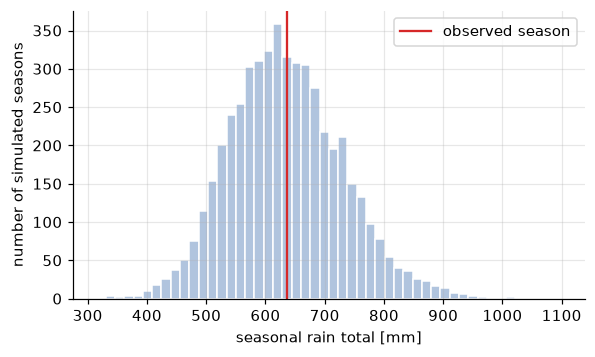

In [12]:
rng = np.random.default_rng(7)
seasons = 5000
wet_mc = rng.random((seasons, 120)) <= p_wet                      # Bernoulli occurrence (inverse transform of uniforms)
amt_mc = stats.gamma.ppf(rng.random((seasons, 120)), alpha_mle, scale=beta_mle)   # gamma amounts (inverse transform)
tot = (wet_mc * amt_mc).sum(axis=1)

obs_tot = rain.sum()
print(f"observed (one synthetic) season total: {obs_tot:.0f} mm")
print(f"simulated totals: mean {tot.mean():.0f} mm, sd {tot.std():.0f} mm, 5-95% range {np.quantile(tot, 0.05):.0f}-{np.quantile(tot, 0.95):.0f} mm")
print(f"theory (independent days): mean {120 * p_wet * alpha_mle * beta_mle:.0f} mm")
print(f"P(a day has more than 50 mm) = {(wet_mc * amt_mc > 50).mean():.4f}   "
      f"(theory p*(1-F(50)) = {p_wet * stats.gamma.sf(50, alpha_mle, scale=beta_mle):.4f})")
plt.figure(figsize=(6, 3.4))
plt.hist(tot, bins=50, color="lightsteelblue", edgecolor="white")
plt.axvline(obs_tot, color="tab:red", label="observed season")
plt.xlabel("seasonal rain total [mm]"); plt.ylabel("number of simulated seasons"); plt.legend();

### The link to quantile mapping (Lecture 18)

Sections 4 and 7 together are a complete bias-correction method. Suppose a model's wet-day rain has CDF $F_m$ and the gauge's has CDF $F_o$. A model value $x_m$ has non-exceedance probability $u=F_m(x_m)$ in the model's own world; the gauge value with the *same* probability is $F_o^{-1}(u)$. So

$$x_{\text{corrected}} = F_o^{-1}\!\big(F_m(x_m)\big).$$

The inner step $F_m$ is the (empirical) CDF of Section 4, the outer step $F_o^{-1}$ is the inverse-transform step of this section. **Quantile mapping is the inverse-transform method with the model's CDF as the uniform generator.** With empirical CDFs both steps need only the sorted samples. The cell below does it for a synthetic "model" that rains too lightly and too uniformly, and Lecture 18 develops the method, its variants and its dangers.

quantiles [mm]            50%      90%      95%      99%
gauge (observed)        6.0     22.1     29.2     41.0
raw model               7.7     19.5     22.8     27.9
corrected model         6.0     21.7     29.1     39.4


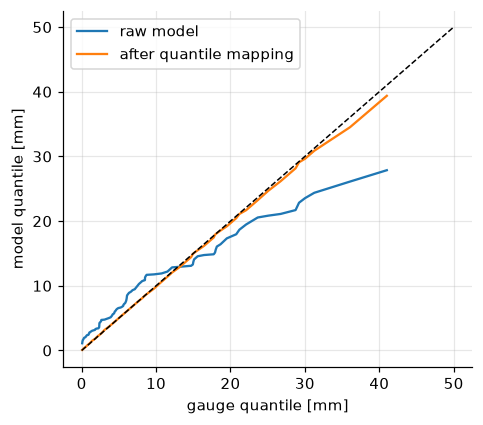

In [13]:
rng = np.random.default_rng(8)
x_mod = rng.gamma(2.0, 4.5, 300)                          # synthetic model wet-day rain [mm]: mean 9 mm but too few extremes

def qmap(x_new, x_model, x_obs):
    """Empirical quantile mapping: u = ECDF of the model (plotting position), then the empirical inverse of the observations."""
    ranks = np.searchsorted(np.sort(x_model), x_new, side="right")
    u_ = np.clip(ranks / (len(x_model) + 1), 1 / (len(x_model) + 1), len(x_model) / (len(x_model) + 1))
    return np.quantile(x_obs, u_)

x_corr = qmap(x_mod, x_mod, x)
pq = np.array([0.5, 0.9, 0.95, 0.99])
print("quantiles [mm]      " + "".join(f"{v:>9.0%}" for v in pq))
for name, arr in (("gauge (observed)", x), ("raw model", x_mod), ("corrected model", x_corr)):
    print(f"{name:18s}" + "".join(f"{v:9.1f}" for v in np.quantile(arr, pq)))
plt.figure(figsize=(4.8, 4.2))
pm = np.linspace(0.01, 0.99, 99)
plt.plot(np.quantile(x, pm), np.quantile(x_mod, pm), label="raw model")
plt.plot(np.quantile(x, pm), np.quantile(x_corr, pm), label="after quantile mapping")
plt.plot([0, 50], [0, 50], "k--", lw=1); plt.xlabel("gauge quantile [mm]"); plt.ylabel("model quantile [mm]"); plt.legend();

The corrected quantiles follow the gauge, by construction. The *calibration* sample is reproduced exactly; whether the correction is trustworthy for a **future** climate is a separate question that Lecture 18 takes up.

# 8) Companion spreadsheet

The file `data/downscaling/lec17/lec17_worked_examples.xlsx` repeats these calculations with live formulas, so you can see each intermediate column. Blue font marks inputs, black marks formulas; hover over a header for a note on its formula.

| Sheet | What it does | Notebook section |
|:--|:--|:--|
| `README` | purpose, colour code, how to use | |
| `Data` | the three synthetic input tables (the same CSVs) | 1 |
| `Gamma_fit` | wet-day probability, exponential fit, gamma by moments (`AVERAGE`, `STDEV.S`), gamma MLE by the closed-form approximation and by a grid search of the log-likelihood (`GAMMALN`), chart of the log-likelihood | 3 |
| `ECDF_GOF` | `SMALL` for the sorted sample, plotting positions, fitted CDFs (`GAMMA.DIST`), KS distance, QQ quantiles (`GAMMA.INV`), charts | 4, 5 |
| `Bivariate` | `CORREL`, `SLOPE`, `INTERCEPT`, `RSQ`, `LINEST`, conditional mean and 90% interval (`NORM.INV`) | 6 |
| `InvTransform` | exponential, gamma, empirical-inverse (`PERCENTILE.INC`), normal and Bernoulli draws from fixed uniform numbers, with round-trip checks | 7 |

The notebook prints the same numbers (for example $\hat\alpha_{\text{MoM}}$ and the closed-form $\hat\alpha_{\text{MLE}}$ above), so you can compare cell by cell. To use your own data, paste it into the blue cells of `Data`.

# Summary

- A distribution is described by its **pdf**, **CDF** and **quantile function**; the summaries are the mean, variance, skewness and quantiles.
- Choose the family by the variable: **Bernoulli/binomial** for wet-day occurrence, **normal** for temperature, **lognormal** for flows, **exponential/gamma** for wet-day amounts, **GEV/Gumbel** for annual maxima.
- **Moments** equate sample and population mean and variance; **maximum likelihood** maximises $\sum\ln f(x_i\mid\theta)$. The normal MLE is $(\bar x, \frac1n\sum(x_i-\bar x)^2)$ and the exponential MLE is $\beta=\bar x$. The gamma MLE solves $\ln\alpha-\psi(\alpha)=\ln\bar x-\overline{\ln x}$ numerically, with $\beta=\bar x/\alpha$, and is more reliable than moments.
- The **empirical CDF** with plotting positions $i/(n+1)$ is the data's own distribution; compare it with the fit by **QQ plot** and **KS distance**, remembering that the textbook KS test is too lenient when the parameters were fitted to the same data, and that tails are poorly constrained.
- For a bivariate normal, $Y\mid x$ is normal with mean $\mu_y+\rho(\sigma_y/\sigma_x)(x-\mu_x)$ and variance $\sigma_y^2(1-\rho^2)$: regression is a conditional mean and leaves a residual spread.
- $F^{-1}(U)$ has CDF $F$ when $U$ is uniform; this generates random numbers from any fitted distribution, and together with the empirical CDF it is **quantile mapping**.

# Check your understanding

1. On a 30-day month with $p=0.4$ independent wet days, what is the mean and variance of the number of wet days? Which distribution is this, and which assumption of real monsoon rain does it break?
2. Derive the maximum-likelihood estimate of the exponential scale $\beta$ from $\ell(\beta)=-n\ln\beta-\sum x_i/\beta$, and explain why the fitted mean of a gamma MLE always equals the sample mean.
3. A sample has mean 8 mm and standard deviation 12 mm. Give the gamma moment estimates. What does a shape below 1 say about the density at zero?
4. Station and model temperatures have $\sigma_x=1$, $\sigma_y=2$ degC and $\rho=0.5$. What are the slope of the regression line and the conditional standard deviation? By what fraction does knowing $x$ reduce the variance of $y$?
5. Using $u=0.9$, an exponential with $\beta=12$ mm and the formula of Section 7, find the draw. Check it by computing $F(x)$. Why is the largest of $n=50$ annual values plotted at $50/51$ and not at $1$?

# Try it yourself

- Replace the synthetic `daily_rain.csv` by a real daily series (for example an IMD grid cell from Lecture 15 for June&ndash;September) and refit; compare the gamma shape with the one here and test the 99% quantile with the exponential.
- Change `alpha_mle` and `beta_mle` in Section 7 and watch the seasonal-total distribution; then make the wet-day probability depend on a "large-scale" index and see what changes.
- Repeat the Monte Carlo test of Section 3 with sample sizes 20, 68 and 300: when does the moment estimate stop being worse than the MLE?
- Add a lognormal fit to the wet-day amounts, then compare its QQ plot and KS distance with the gamma's.
- In the spreadsheet, change the blue grid inputs in `Gamma_fit` (start and step) and watch how the grid-search estimate tracks the exact one.

```{note} Sources
Written for **CE524 Applied Hydroclimatology**. The concepts follow Chapter 2 (Statistical background) of Lee, T., & Singh, V. P. (2019). *Statistical Downscaling for Hydrological and Environmental Applications*. CRC Press: Section 2.1 (random variables, the distributions, parameter estimation by moments and maximum likelihood, empirical distribution and plotting positions), Section 2.2 (multivariate normal, covariance and correlation, conditional distribution) and Section 2.3 (random number generation and the inverse-transform method). The derivations, the data, the code and all figures are original to this course; the book's examples and data are not reproduced.

All data in this lecture are **synthetic**, produced with fixed random seeds (`data/downscaling/lec17/`), and do not describe any real station or model. For real work use observations (for example IMD gridded rainfall and temperature) and a CMIP6 or NEX-GDDP-CMIP6 series for the model. The closed-form gamma shape approximation used in the spreadsheet is a standard approximation to the exact maximum-likelihood equation; the exact root is computed in the notebook for comparison. Note that the sign convention of the GEV shape parameter differs between textbooks and software.

Text under CC BY-SA 4.0, code additionally under the MIT License; full attribution in [CREDITS.md](https://github.com/drvivekhydro/hydroclimatology/blob/main/CREDITS.md).
```